### **Supervised Learning**

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

### Addressing Class Imbalance: Undersampling, Oversampling

რა არის კლასთა დისბალანსი?  
კლასთა დისბალანსი ხდება მაშინ, როდესაც ერთ-ერთი კლასი ბევრად მეტია მეორეზე.  
მაგალითად:
- თაღლითობის აღმოჩენა → 98% ტრანზაქცია ლეგალურია, 2% თაღლითური.
- სამედიცინო დიაგნოზი → 95% ჯანმრთელი, 5% დაავადებული.

კლასთა დისბალანსი პრობლემაა, კლასიფიკაციის ალგორითმები ცუდად სწავლობენ იშვიათ კლასებზე, ისინი უფრო ხშირად მრავალრიცხოვან კლასზე ფოკუსირდებიან.  
მიზანი: კლასთა რაოდენობის დაბალანსება, რათა მოდელმა სწორად ამოიცნოს იშვიათი კლასები.  

---

#### Undersampling
Undersampling გულისხმობს მრავალრიცხოვანი კლასის შემცირებას, რათა მონაცემთა ბალანსი გავათანაბროთ.  

როდის გამოვიყენოთ?  
- როცა ბევრი მონაცემი გვაქვს, მაგრამ ერთ-ერთი კლასი ჭარბობს.  
- როცა გარკვეული რაოდენობის მონაცემების მოცილება მაინც არ იმოქმედებს საბოლოო შედეგზე.  

In [3]:
# მონაცემების შექმნა (1000 ნიმუში, სადაც 900 - კლასი 0, 100 - კლასი 1)
X = np.random.rand(1000, 2)
y = np.array([0] * 900 + [1] * 100)  # დისბალანსი (90% vs 10%)

# Random Undersampling (მრავალრიცხოვანი კლასის შემცირება)
undersampler = RandomUnderSampler(random_state=42)
X_resampled, y_resampled = undersampler.fit_resample(X, y)

# შედეგი
print(f"თავდაპირველი განაწილება: {np.bincount(y)}")
print(f"ახალი განაწილება: {np.bincount(y_resampled)}")

#მოდელი უკეთ სწავლობს ორივე კლასს, მაგრამ შესაძლოა დავკარგოთ მნიშვნელოვანი ინფორმაცია.  

თავდაპირველი განაწილება: [900 100]
ახალი განაწილება: [100 100]


#### Oversampling
Oversampling ნიშნავს იშვიათი კლასის ნიმუშების გაზრდას, რათა მონაცემთა განაწილება დაბალანსდეს.  

✔ როდის გამოვიყენოთ?  
- როცა ძალიან ცოტა მონაცემი გვაქვს იშვიათი კლასისთვის.  

In [4]:
# Random Oversampling (იშვიათი კლასის გაზრდა)
oversampler = RandomOverSampler(random_state=42)
X_resampled, y_resampled = oversampler.fit_resample(X, y)

# შედეგი
print(f"თავდაპირველი განაწილება: {np.bincount(y)}")
print(f"ახალი განაწილება: {np.bincount(y_resampled)}")

# Oversampling ზრდის იშვიათი კლასის რაოდენობას, მაგრამ შეიძლება გამოიწვიოს Overfitting.  

თავდაპირველი განაწილება: [900 100]
ახალი განაწილება: [900 900]


#### SMOTE (Synthetic Minority Oversampling Technique)
SMOTE არის უმჯობესებული Oversampling მეთოდი, რომელიც ახალ ნიმუშებს ქმნის, ნაცვლად იმავე მონაცემების გამეორებისა.  

In [5]:
# SMOTE Oversampling
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# შედეგი
print(f"თავდაპირველი განაწილება: {np.bincount(y)}")
print(f"ახალი განაწილება: {np.bincount(y_resampled)}")

# SMOTE ქმნის ახალ მონაცემებს და ამცირებს Overfitting-ის რისკს.

თავდაპირველი განაწილება: [900 100]
ახალი განაწილება: [900 900]


#### როდის რომელი მეთოდი გამოვიყენოთ?
| მეთოდი | როდის გამოვიყენოთ? | რისკები |
|------------|----------------|------------|
| Undersampling | როცა გვაქვს ბევრი მონაცემი, მაგრამ ერთ-ერთი კლასი ჭარბობს | შეიძლება დავკარგოთ მნიშვნელოვანი ინფორმაცია |
| Oversampling | როცა იშვიათი კლასის მონაცემები ცოტაა | შეიძლება გამოიწვიოს Overfitting |
| SMOTE | როცა გვჭირდება ახალი სინთეზური მონაცემები | ახალი მონაცემები შეიძლება არ იყოს რეალური |

- დიდ მონაცემებზე → Undersampling მუშაობს უკეთ.  
- მცირე მონაცემებზე → Oversampling ან SMOTE უმჯობესია.  

In [6]:
# Load dataset
data = load_breast_cancer()
df_cancer = pd.DataFrame(data.data, columns=data.feature_names)
target_map = dict(enumerate(data.target_names))
df_cancer["target"] = pd.Series(data.target).map(target_map)
df_cancer.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [7]:
# მახასიათებლების (X) და სამიზნის (y) გამოყოფა
X = df_cancer.drop("target", axis=1)
y = df_cancer["target"]

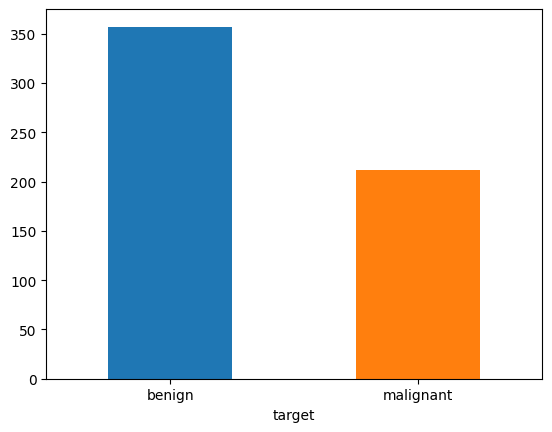

In [8]:
y.value_counts().plot(kind="bar", color=["C0", "C1"])
plt.xticks(rotation=0);

In [9]:
# მონაცემთა გაყოფა სასწავლო (80%) და სატესტო (20%) ნაწილებად
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

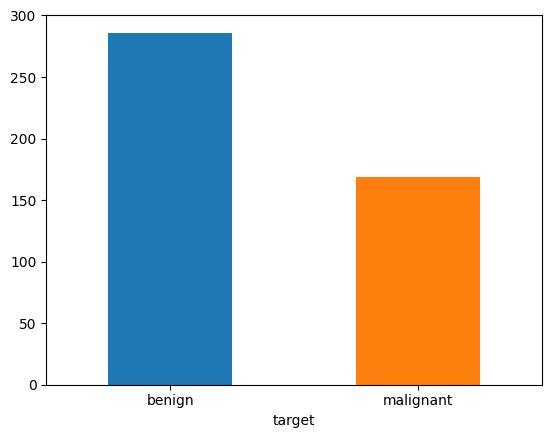

In [10]:
# y_train-ის განაწილება
y_train.value_counts().plot(kind="bar", color=["C0", "C1"])
plt.xticks(rotation=0);

In [11]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [12]:
# ლოგისტიკური რეგრესიის მოდელის შექმნა და გაწვრთნა
model = LogisticRegression(max_iter=100)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [13]:
# პროგნოზირება
y_pred = model.predict(X_test)

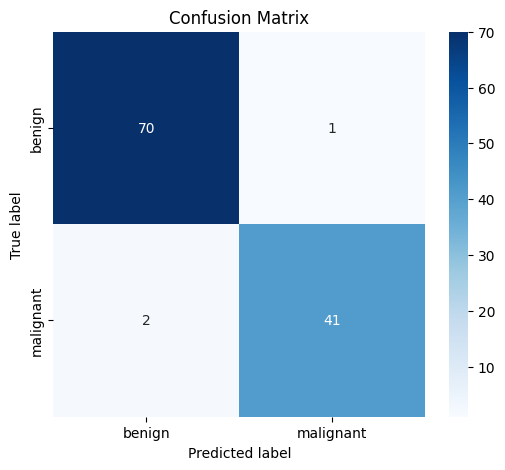

In [14]:
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()


Undersampled class distribution:


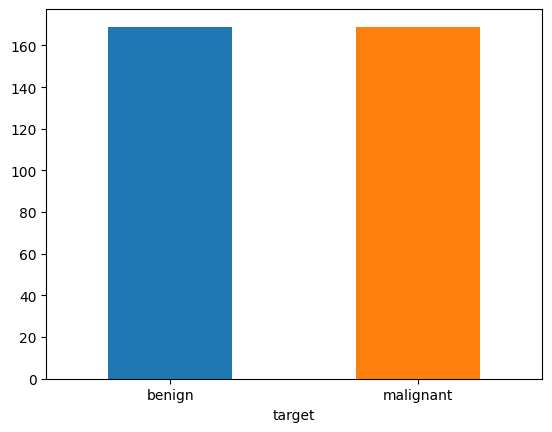

In [15]:
# Undersampling
rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X_train, y_train)

print("\nUndersampled class distribution:")
y_under.value_counts().plot(kind="bar", color=["C0", "C1"])
plt.xticks(rotation=0);

In [16]:
# ლოგისტიკური რეგრესიის მოდელის შექმნა და გაწვრთნა
model = LogisticRegression(max_iter=100)
model.fit(X_under, y_under)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [17]:
# პროგნოზირება
y_pred = model.predict(X_test)

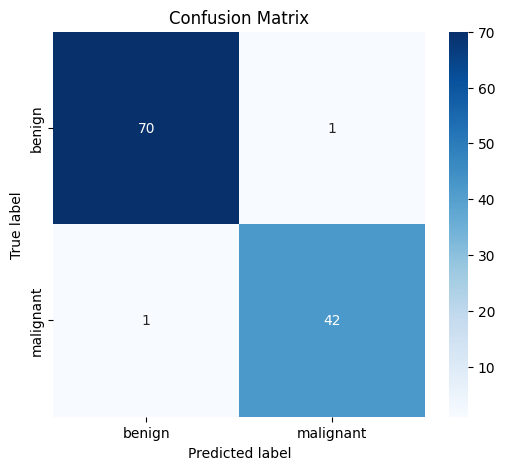

In [18]:
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()


Oversampled class distribution:


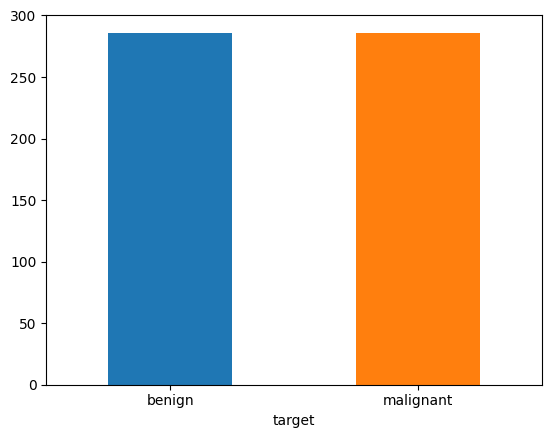

In [19]:
# Oversampling
ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X_train, y_train)

print("\nOversampled class distribution:")
y_over.value_counts().plot(kind="bar", color=["C0", "C1"])
plt.xticks(rotation=0);

In [20]:
# ლოგისტიკური რეგრესიის მოდელის შექმნა და გაწვრთნა
model = LogisticRegression(max_iter=100)
model.fit(X_over, y_over)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [21]:
# პროგნოზირება
y_pred = model.predict(X_test)

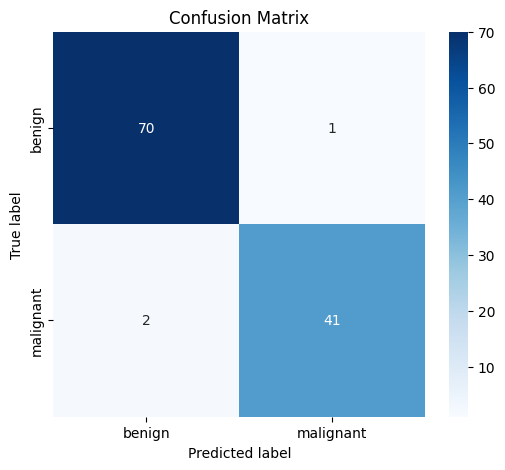

In [22]:
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()


SMOTE class distribution:


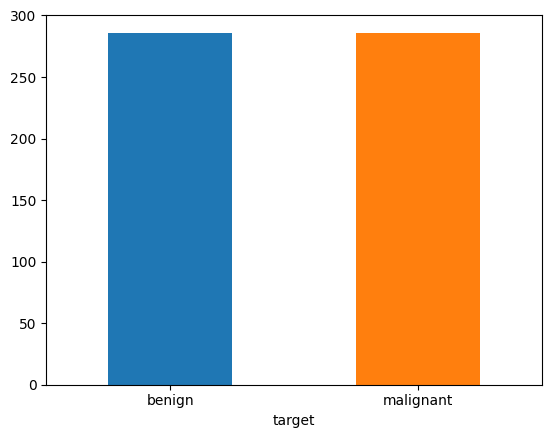

In [23]:
# SMOTE
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X_train, y_train)
print("\nSMOTE class distribution:")
y_smote.value_counts().plot(kind="bar", color=["C0", "C1"])
plt.xticks(rotation=0);

In [24]:
# ლოგისტიკური რეგრესიის მოდელის შექმნა და გაწვრთნა
model = LogisticRegression(max_iter=100)
model.fit(X_smote, y_smote)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [25]:
# პროგნოზირება
y_pred = model.predict(X_test)

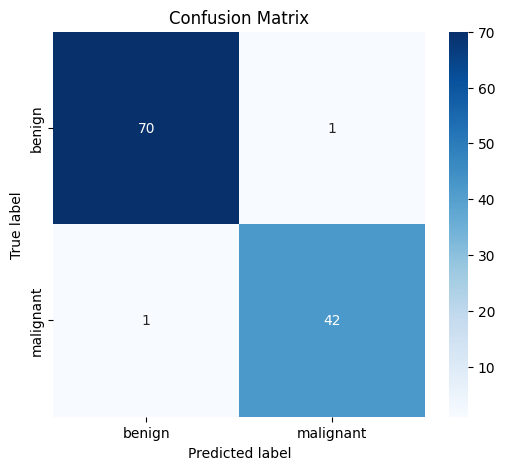

In [26]:
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

### Gradient Boosting

Gradient Boosting ეფუძნება Boosting-ის პრინციპს. Boosting წარმოადგენს მეთოდს, რომელიც აერთიანებს რამდენიმე სუსტ მოდელს (გადაწყვეტილების ხეებს), რათა შეიქმნას ძლიერი მოდელი. ამ პროცესში ყოველი ახალი მოდელი მიზნად ისახავს წინა მოდელების შეცდომების კორექციას.

---
Gradient Boosting მუშაობს იტერაციულად და ქმნის გადაწყვეტილების ხეების მიმდევრობას, სადაც ყოველი ახალი ხე ცდილობს წინა ხის შეცდომების შესწორებას.

1. ინიციალიზაცია – მოდელი იწყებს მუშაობას მარტივი შეფასებით (მაგალითად, სამიზნე ცვლადის საშუალო მნიშვნელობით).                                      
2. residual-ების გამოთვლა – გამოითვლება ცდომილება ნამდვილ და პროგნოზირებულ მნიშვნელობების შორის.                                                     
3. ხის გაწრთვნა – ახალი გადაწყვეტილების ხე იწრთვნება residual-ების მინიმიზაციისთვის.                                                                  
4. მოდელის განახლება – ახალი ხის პროგნოზი ემატება უკვე არსებულ პროგნოზს განსაზღვრული სასწავლო სიჩქარის კოეფიციენტით.                                   
5. გამეორება – ნაბიჯები 2-4 მეორდება, სანამ არ მივიღებთ სასურველი რაოდენობის ხეებს ან მოდელი არ შეწყვეტს გაუმჯობესებას.  

Input:
  - X, y_actual          - მახასიათებლები და სამიზნე ცვლადი
  - M                    - ხეების რაოდენობა
  - learning_rate        - სწავლის სიჩქარე

1. საწყისი პროგნოზი:
    y_pred = საშუალო(y_actual)

2. ბუსტინგის მარყუჟი (M-ჯერ):
    - გამოთვალე ცდომილება: 
        residual = y_actual - y_pred
    - ისწავლე decision tree ამ ცდომილებაზე:
        tree = შეასწავლე(X, residual)
    - გააკეთე ახალი პროგნოზი ამ ხით:
        update = tree.predict(X)
    - განაახლე y_pred:
        y_pred = y_pred + learning_rate * update

3. საბოლოო y_pred -  პროგნოზია

<img src="../../images/gradient_boosting.png" alt="gradient boosting" width=600>

ვთქვათ:

* $y = 10$
* პროგნოზი (საშუალო): $F₀ = 6$
* ნაშთი: $r₁ = 10 - 6 = 4$

decision tree პროგნოზირებს ნაშთს:

* $h₁ = 3.5$

ამ ხეს ვიყენებთ მიმდინარე მოდელის გასაუმჯობესებლად:

$$
F_1 = 6 + 0.1 \cdot 3.5 = 6.35
$$

ახალი error:

$$
r_2 = 10 - 6.35 = 3.65
$$

→ error შემცირდა. ზუსტად ამაში მდგომარეობს utilizing.

## მთავარი პარამეტრები
პარამეტრი | ახსნა
-------------------------|------------------
n_estimators | მოდელის მიერ გამოყენებული ხეების რაოდენობა
learning_rate | ყოველი ხის წვლილის წონა საბოლოო პროგნოზში
max_depth | თითოეული ხის მაქსიმალური სიღრმე

### შედარება: Gradient Boosting vs. Random Forest კლასიფიკაციისთვის

| მახასიათებელი           | Gradient Boosting | Random Forest |
|-------------------------|------------------|--------------|
| Ensemble Type     | Boosting (მიმდევრული) | Bagging (პარალელური) |
| Overfitting (Overfitting) | ნაკლებად მიდრეკილია | უფრო მგრძნობიარეა, თუ ბევრი ხეა |
| Computational Cost  | მაღალი (მიმდევრული გამოთვლები) | დაბალი (პარალელიზაციის შესაძლებლობა) |
| Robustness to Outliers | კარგი (სასწავლო სიჩქარით რეგულირდება) | შეიძლება იყოს მგრძნობიარე |
| Accuracy on Complex Data | ძალიან მაღალი | მაღალი |


#### **Titanic Dataset**: პროგნოზირება, გადარჩება თუ არა მგზავრი Titanic-ის კატასტროფის დროს.

In [83]:
# Titanic Dataset-ის ჩატვირთვა (Open Source)
url_titanic = "https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv"
df_titanic = pd.read_csv(url_titanic)
df_titanic.head()

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [84]:
# მონაცემთა წინასწარი დამუშავება (Feature Engineering)
df_titanic = df_titanic.drop(columns=["Name", "Pclass"])  # არასაჭირო სვეტების წაშლა

label_encoder = LabelEncoder()
df_titanic["Sex"] = label_encoder.fit_transform(df_titanic["Sex"])

In [85]:
# ცვლადების გამოყოფა (Features & Target)
X = df_titanic.drop(["Survived"], axis=1)  # Features (დამოუკიდებელი ცვლადები)
y = df_titanic["Survived"]  # Target (დამოკიდებული ცვლადი)

# მონაცემთა გაყოფა (Train-Test Split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [86]:
# GradientBoosting კლასიფიკატორის გაწვრთნა
model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
model.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [87]:
# პროგნოზი
y_pred = model.predict(X_test)

In [32]:
# შეფასება
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.83

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.86      0.86       111
           1       0.77      0.76      0.77        67

    accuracy                           0.83       178
   macro avg       0.81      0.81      0.81       178
weighted avg       0.83      0.83      0.83       178



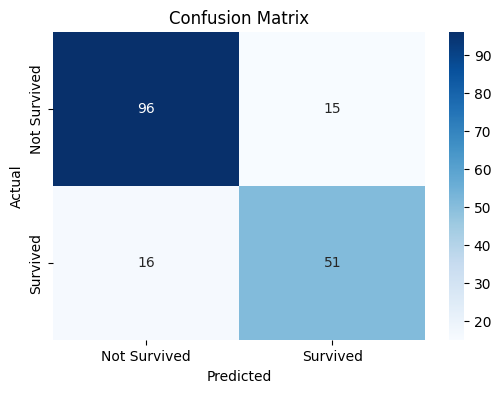

In [33]:
# Confusion Matrix ვიზუალიზაცია
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Survived", "Survived"], yticklabels=["Not Survived", "Survived"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

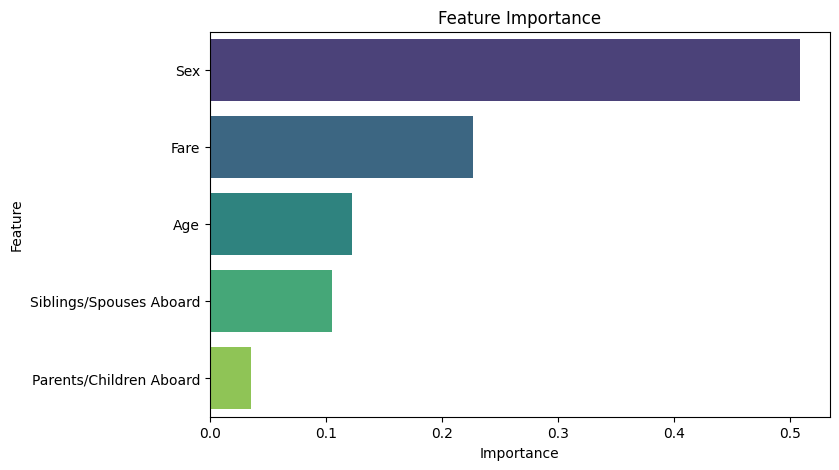

In [34]:
# Feature Importance
importance_df = pd.DataFrame({"Feature": X.columns, "Importance": model.feature_importances_})
importance_df = importance_df.sort_values(by="Importance", ascending=False)

# შედეგების ვიზუალიზაცია
plt.figure(figsize=(8, 5))
sns.barplot(x=importance_df["Importance"], y=importance_df["Feature"], palette="viridis")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance");

#### California Housing Data - სახლის ფასის პროგნოზი

In [88]:
# Load the dataset
data = fetch_california_housing()
X, y = data.data, data.target * 100000
feature_names = data.feature_names

df_housing = pd.DataFrame(X, columns=feature_names)
df_housing["MedHouseVal"] = y 
df_housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,452600.0
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,358500.0
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,352100.0
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,341300.0
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,342200.0


In [89]:
# მონაცემთა გაყოფა (Train-Test Split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [90]:
# Gradient Boosting Regressor-ის გაწვრთნა
gb_reg = GradientBoostingRegressor(n_estimators=1000, learning_rate=0.1, max_depth=4, random_state=42)
gb_reg.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,1000
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,4
,min_impurity_decrease,0.0
,init,None


In [91]:
# პროგნოზი
y_pred = gb_reg.predict(X_test)

In [92]:
# მოდელის ევალუაცია
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - $
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - $²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - $
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 29950.25
Mean Squared Error (MSE): 2112936855.54
Root Mean Squared Error (RMSE): 45966.69
R² Score: 0.84


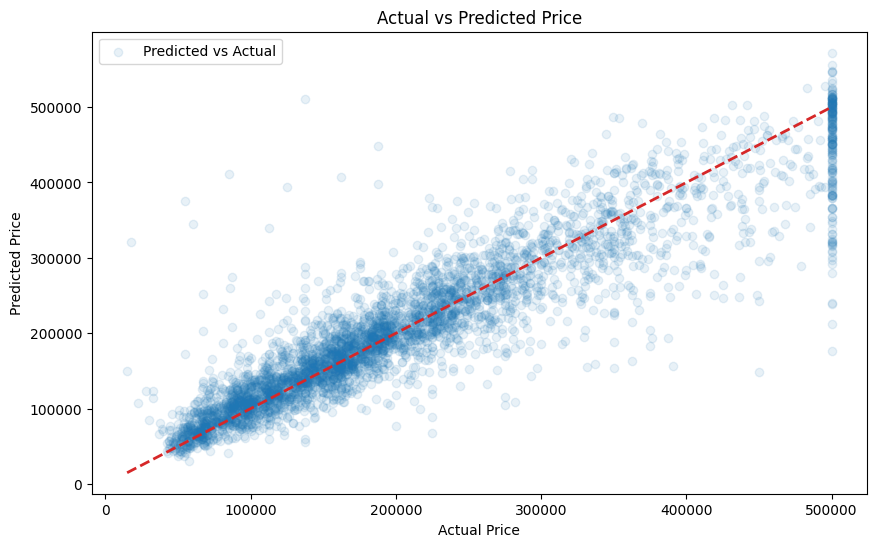

In [93]:
# Actual vs predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.1, label="Predicted vs Actual")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color="C3", linestyle="dashed", linewidth=2)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.legend()
plt.show()

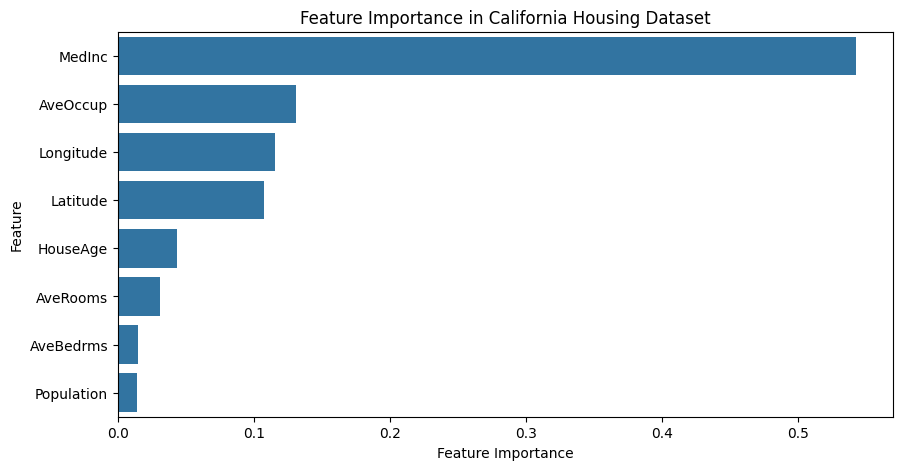

In [41]:
# Feature Importance
feature_importances = pd.Series(gb_reg.feature_importances_, index=feature_names)
top_features = feature_importances.sort_values(ascending=False)[:10]

plt.figure(figsize=(10,5))
sns.barplot(x=top_features.values, y=top_features.index)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance in California Housing Dataset")
plt.show()

|                  | `GradientBoostingClassifier` / `GradientBoostingRegressor` (sklearn) | XGBoost (`xgboost.XGBClassifier` / `XGBRegressor`)           |
| --------------------------- | -------------------------------------------------------------------- | ------------------------------------------------------------ |
| ალგორითმის ტიპი                 | კლასიკური Gradient Boosting                       | გაუმჯობესებული Gradient Boosting მრავალ ოპტიმიზაციით |
| სისწრაფე                        | ნელი, ძირითადად single-threaded                      | ძალიან სწრაფი, Multi-Core     |
| პარალელიზაცია                   | შეზღუდული პარალელიზაცია                       | სრული პარალელიზაცია ტრენიგისას                   |               |
| რეგულარიზაცია                   | საბაზისო (max_depth, learning_rate, n_estimators) | ძლიერი: L1, L2, gamma, min_child_weight და სხვა      |
| ხის სტრუქტურა                   | პატარა, მარტივი ხეები | უფრო ღრმა ხეები      |
| Overfitting-ის კონტროლი         | საშუალო                                           | ძალიან ძლიერი, ბევრი პარამეტრით                      |
| მეხსიერების გამოყენება          | მაღალი                                       | ეფექტური მეხსიერების გამოყენება                      |
| ჰიპერპარამეტრების ტუნინგი       | მარტივი, ცოტა პარამეტრი                           | რთული, მაგრამ მოქნილი და ძლიერი მოდელი               |
| შესაფერისი dataset ზომა         | პატარა–საშუალო                                    | საშუალო–დიდი, მაღალი სკალირებადობა                   |

### XGBoost Regressor

In [42]:
# XGBoost Regressor-ის გაწვრთნა
xgb_reg = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)

xgb_reg.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [43]:
# პროგნოზი
y_pred = xgb_reg.predict(X_test)

In [44]:
# მოდელის ევალუაცია
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - $
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - $²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - $
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 29540.02
Mean Squared Error (MSE): 2069623239.11
Root Mean Squared Error (RMSE): 45493.11
R² Score: 0.84


### XGBoost Classifier

In [45]:
# ცვლადების გამოყოფა (Features & Target)
X = df_titanic.drop(["Survived"], axis=1)  # Features (დამოუკიდებელი ცვლადები)
y = df_titanic["Survived"]  # Target (დამოკიდებული ცვლადი)

# მონაცემთა გაყოფა (Train-Test Split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [75]:
# XGBoost Classifier-ის ინიციალიზაცია
xgb_clf = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
)

# მოდელის გაწვრთნა
xgb_clf.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [76]:
# პროგნოზი
y_pred = xgb_clf.predict(X_test)

In [77]:
# შეფასება
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.81

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.87      0.85       111
           1       0.77      0.72      0.74        67

    accuracy                           0.81       178
   macro avg       0.81      0.80      0.80       178
weighted avg       0.81      0.81      0.81       178



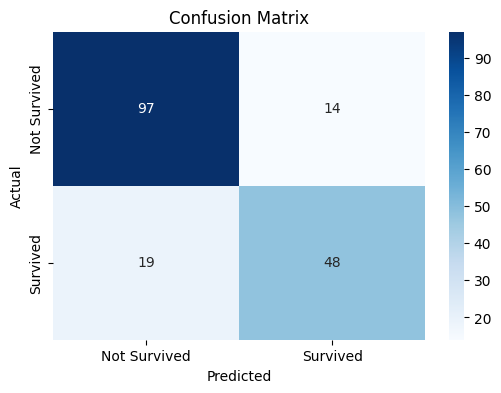

In [78]:
# Confusion Matrix ვიზუალიზაცია
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Survived", "Survived"], yticklabels=["Not Survived", "Survived"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()